# 02 SQL 分析：核心指标、转化漏斗、留存与时间规律

这一部分全部用 SQL 完成（在 Python 里通过 DuckDB 执行），覆盖互联网数据分析面试最常考的几类问题：

1. **核心指标**：浏览量、独立访客数、购买转化率、复购率
2. **转化漏斗**：浏览 → 收藏或加购 → 购买，定位流失最严重的环节
3. **购买路径**：用户在买一件商品之前，是直接买，还是先加购或收藏
4. **留存分析**：用窗口函数计算同期群留存、次日回访率和复购间隔
5. **时间规律**：一天中的活跃高峰、周末与工作日的差异，并做显著性检验
6. **类目分析**：找出"高浏览、低转化"的类目

用到的 SQL 技巧：`COUNT(*) FILTER`、`CASE WHEN`、公用表表达式（`WITH`）、窗口函数（`MIN() OVER`、`LAG`、`LEAD`、`SUM() OVER`）。

In [1]:
# 在 Google Colab 上运行时先执行这一格；在自己电脑上运行会自动跳过
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/ecommerce-user-behavior/notebooks")
    subprocess.run("pip -q install duckdb xgboost", shell=True, check=True)
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True, check=True)
    import matplotlib.font_manager as fm
    for f in fm.findSystemFonts():
        if "NotoSansCJK" in f:
            fm.fontManager.addfont(f)
    print("Colab 环境准备完成，当前目录：", os.getcwd())

Mounted at /content/drive
Colab 环境准备完成，当前目录： /content/drive/MyDrive/ecommerce-user-behavior/notebooks


In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import config, utils

utils.setup_plot()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
con = utils.connect()
q = lambda sql: con.execute(sql).df()

BLUE, ORANGE, GREY = "#3B6FB6", "#E07B39", "#9AA5B1"

## 1. 核心指标

In [3]:
overview = q('''
    WITH per_user AS (
        SELECT
            user_id,
            COUNT(*)                                                   AS actions,
            COUNT(*) FILTER (WHERE behavior_type = 'pv')               AS pv,
            COUNT(*) FILTER (WHERE behavior_type = 'buy')              AS buys,
            COUNT(DISTINCT event_date) FILTER (WHERE behavior_type = 'buy') AS buy_days
        FROM ub
        GROUP BY user_id
    )
    SELECT
        SUM(pv)                                                AS 浏览量,
        COUNT(*)                                               AS 独立访客数,
        SUM(pv) / COUNT(*)                                     AS 人均浏览量,
        COUNT(*) FILTER (WHERE buys > 0)                       AS 购买用户数,
        COUNT(*) FILTER (WHERE buys > 0) / COUNT(*)            AS 用户购买转化率,
        SUM(buys) / NULLIF(COUNT(*) FILTER (WHERE buys > 0), 0) AS 购买用户人均购买次数,
        COUNT(*) FILTER (WHERE buy_days >= 2)
            / NULLIF(COUNT(*) FILTER (WHERE buys > 0), 0)      AS 复购率,
        COUNT(*) FILTER (WHERE pv = actions) / COUNT(*)        AS 仅浏览未互动用户占比
    FROM per_user
''')
overview.T.rename(columns={0: "值"})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,值
浏览量,"8,966,055.0000"
独立访客数,"99,057.0000"
人均浏览量,90.5141
购买用户数,"67,293.0000"
用户购买转化率,0.6793
购买用户人均购买次数,2.9875
复购率,0.5504
仅浏览未互动用户占比,0.0602


**指标口径：**
- 用户购买转化率 = 有过购买的用户 ÷ 全部用户
- 复购率 = 在两天及以上有购买的用户 ÷ 有过购买的用户（按天计，避免一次下多单被算成复购）
- 仅浏览未互动用户占比 = 只有浏览、没有收藏、加购和购买的用户 ÷ 全部用户（类似"跳失率"）

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,日期,浏览量,活跃用户数,购买用户数,当日购买转化率,是否周末
0,2017-11-25,940490,70753,13335,0.1885,True
1,2017-11-26,951821,71659,13639,0.1903,True
2,2017-11-27,903363,71009,14603,0.2056,False
3,2017-11-28,881430,71174,14092,0.1980,False
4,2017-11-29,925067,72118,14626,0.2028,False
5,2017-11-30,935711,73066,14454,0.1978,False
6,2017-12-01,976096,74036,14014,0.1893,False
7,2017-12-02,1226597,97264,17540,0.1803,True
8,2017-12-03,1225480,96973,17239,0.1778,True


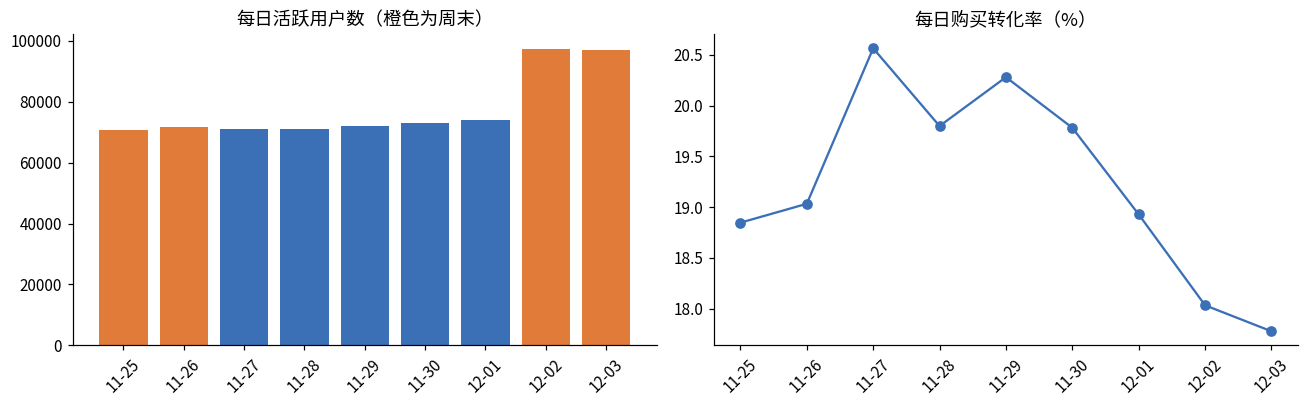

In [4]:
daily = q('''
    SELECT
        event_date                                                   AS 日期,
        COUNT(*) FILTER (WHERE behavior_type = 'pv')                 AS 浏览量,
        COUNT(DISTINCT user_id)                                      AS 活跃用户数,
        COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'buy') AS 购买用户数,
        COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'buy')
            / COUNT(DISTINCT user_id)                                AS 当日购买转化率,
        ANY_VALUE(is_weekend)                                        AS 是否周末
    FROM ub
    GROUP BY event_date
    ORDER BY event_date
''')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
labels = pd.to_datetime(daily["日期"]).dt.strftime("%m-%d")
axes[0].bar(labels, daily["活跃用户数"], color=[ORANGE if w else BLUE for w in daily["是否周末"]])
axes[0].set_title("每日活跃用户数（橙色为周末）")
axes[1].plot(labels, daily["当日购买转化率"] * 100, marker="o", color=BLUE)
axes[1].set_title("每日购买转化率（%）")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
_ = utils.save_fig(fig, "02_每日趋势")
daily

## 2. 转化漏斗

分两个口径看：
- **用户口径**：有多少人走到了下一步（严格逐层，下一层必须同时满足上一层）
- **行为口径**：每一步的行为次数

,环节,用户数,环节转化率,整体转化率
0,1 浏览,98640,NaN,1.0000
1,2 收藏或加购,85757,0.8694,0.8694
2,3 购买,60040,0.7001,0.6087


,次数,环节转化率
浏览次数,8966055,NaN
收藏或加购次数,843626,0.0941
购买次数,201037,0.2383


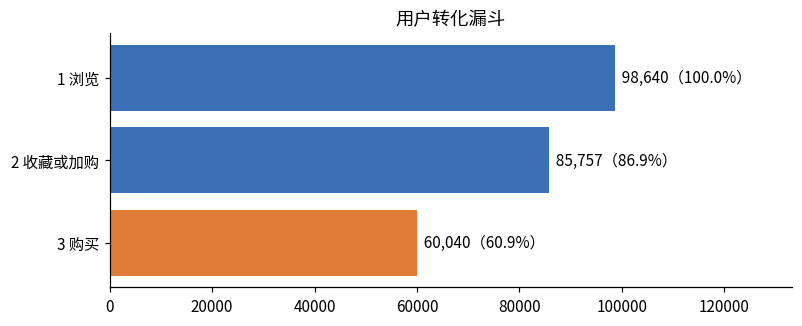

In [5]:
funnel_user = q('''
    WITH flags AS (
        SELECT
            user_id,
            bool_or(behavior_type = 'pv')                  AS has_pv,
            bool_or(behavior_type IN ('fav', 'cart'))      AS has_fav_cart,
            bool_or(behavior_type = 'buy')                 AS has_buy
        FROM ub
        GROUP BY user_id
    )
    SELECT '1 浏览' AS 环节, COUNT(*) FILTER (WHERE has_pv) AS 用户数 FROM flags
    UNION ALL
    SELECT '2 收藏或加购', COUNT(*) FILTER (WHERE has_pv AND has_fav_cart) FROM flags
    UNION ALL
    SELECT '3 购买', COUNT(*) FILTER (WHERE has_pv AND has_fav_cart AND has_buy) FROM flags
    ORDER BY 环节
''')
funnel_user["环节转化率"] = funnel_user["用户数"] / funnel_user["用户数"].shift(1)
funnel_user["整体转化率"] = funnel_user["用户数"] / funnel_user["用户数"].iloc[0]

funnel_action = q('''
    SELECT
        COUNT(*) FILTER (WHERE behavior_type = 'pv')              AS 浏览次数,
        COUNT(*) FILTER (WHERE behavior_type IN ('fav', 'cart'))  AS 收藏或加购次数,
        COUNT(*) FILTER (WHERE behavior_type = 'buy')             AS 购买次数
    FROM ub
''').T.rename(columns={0: "次数"})
funnel_action["环节转化率"] = funnel_action["次数"] / funnel_action["次数"].shift(1)

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(funnel_user["环节"][::-1], funnel_user["用户数"][::-1], color=[ORANGE, BLUE, BLUE])
for i, (n, r) in enumerate(zip(funnel_user["用户数"][::-1], funnel_user["整体转化率"][::-1])):
    ax.text(n, i, f"  {n:,.0f}（{r:.1%}）", va="center")
ax.set_title("用户转化漏斗")
ax.set_xlim(0, funnel_user["用户数"].max() * 1.35)
_ = utils.save_fig(fig, "02_用户转化漏斗")

display(funnel_user)
display(funnel_action)

## 3. 购买路径：买之前先加购还是直接买？

以"用户-商品"为单位，看每一笔购买之前有没有发生过收藏或加购，并计算"加购后最终购买"的比例。

In [6]:
paths = q('''
    WITH pair AS (
        SELECT
            user_id, item_id,
            MIN(ts) FILTER (WHERE behavior_type = 'buy')  AS first_buy,
            MIN(ts) FILTER (WHERE behavior_type = 'cart') AS first_cart,
            MIN(ts) FILTER (WHERE behavior_type = 'fav')  AS first_fav
        FROM ub
        GROUP BY user_id, item_id
    )
    SELECT
        CASE
            WHEN first_cart <= first_buy AND first_fav <= first_buy THEN '收藏且加购后购买'
            WHEN first_cart <= first_buy                            THEN '加购后购买'
            WHEN first_fav  <= first_buy                            THEN '收藏后购买'
            ELSE '浏览后直接购买'
        END                                AS 购买路径,
        COUNT(*)                           AS 购买的商品数,
        COUNT(*) / SUM(COUNT(*)) OVER ()   AS 占比
    FROM pair
    WHERE first_buy IS NOT NULL
    GROUP BY 1
    ORDER BY 购买的商品数 DESC
''')

after_action = q('''
    WITH pair AS (
        SELECT
            user_id, item_id,
            MIN(ts) FILTER (WHERE behavior_type = 'buy')  AS first_buy,
            MIN(ts) FILTER (WHERE behavior_type = 'cart') AS first_cart,
            MIN(ts) FILTER (WHERE behavior_type = 'fav')  AS first_fav
        FROM ub
        GROUP BY user_id, item_id
    )
    SELECT
        COUNT(*) FILTER (WHERE first_cart IS NOT NULL AND first_buy >= first_cart)
            / COUNT(*) FILTER (WHERE first_cart IS NOT NULL)                         AS 加购商品的购买率,
        COUNT(*) FILTER (WHERE first_fav IS NOT NULL AND first_buy >= first_fav)
            / COUNT(*) FILTER (WHERE first_fav IS NOT NULL)                          AS 收藏商品的购买率,
        COUNT(*) FILTER (WHERE first_cart IS NULL AND first_fav IS NULL AND first_buy IS NOT NULL)
            / COUNT(*) FILTER (WHERE first_cart IS NULL AND first_fav IS NULL)       AS 仅浏览商品的购买率
    FROM pair
''')
display(paths)
after_action.T.rename(columns={0: "值"})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,购买路径,购买的商品数,占比
0,浏览后直接购买,148540,0.7730
1,加购后购买,31604,0.1645
2,收藏后购买,10745,0.0559
3,收藏且加购后购买,1271,0.0066


,值
加购商品的购买率,0.0610
收藏商品的购买率,0.0417
仅浏览商品的购买率,0.0215


## 4. 留存分析（窗口函数）

**4.1 同期群留存：** 按用户在数据中第一次出现的日期分组，看之后每一天还有多少人回来。
`MIN(event_date) OVER (PARTITION BY user_id)` 求每个用户的首次活跃日。

> 注意：数据集只截取了 9 天，"首次出现"不等于真正的新用户。面试时主动说明这个口径限制，比只报数字更加分。

首日（11-25）同期群：70,753 人，次日留存 78.9%，七日留存 98.5%


day_n,首日人数,0,1,2,3,4,5,6,7,8
cohort_date,,,,,,,,,,
11-25,"70,753.0000",1.0000,0.7888,0.7674,0.7600,0.7604,0.7648,0.7704,0.9849,0.9824
11-26,"15,849.0000",1.0000,0.6506,0.6502,0.6600,0.6708,0.6866,0.9782,0.9739,NaN
11-27,"6,400.0000",1.0000,0.6111,0.6258,0.6277,0.6600,0.9741,0.9700,NaN,NaN
11-28,"3,185.0000",1.0000,0.6270,0.6305,0.6647,0.9673,0.9630,NaN,NaN,NaN
11-29,"1,855.0000",1.0000,0.7040,0.7288,0.9682,0.9612,NaN,NaN,NaN,NaN
11-30,992.0000,1.0000,0.9375,0.9516,0.9546,NaN,NaN,NaN,NaN,NaN
12-01,22.0000,1.0000,0.8182,1.0000,NaN,NaN,NaN,NaN,NaN,NaN
12-02,1.0000,1.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


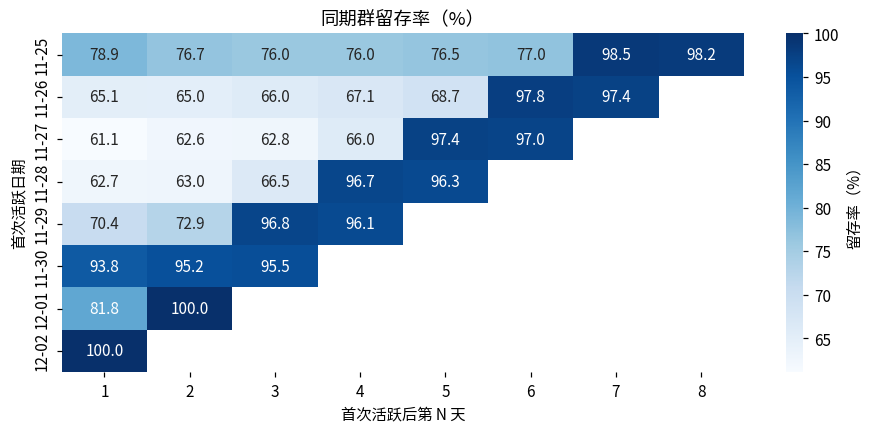

In [7]:
cohort = q('''
    WITH daily AS (
        SELECT DISTINCT user_id, event_date FROM ub
    ),
    tagged AS (
        SELECT
            user_id, event_date,
            MIN(event_date) OVER (PARTITION BY user_id) AS cohort_date
        FROM daily
    )
    SELECT
        cohort_date,
        date_diff('day', cohort_date, event_date) AS day_n,
        COUNT(*)                                  AS users
    FROM tagged
    GROUP BY cohort_date, day_n
    ORDER BY cohort_date, day_n
''')
pivot = cohort.pivot(index="cohort_date", columns="day_n", values="users")
retention = pivot.div(pivot[0], axis=0)
retention.index = pd.to_datetime(retention.index).strftime("%m-%d")
retention.insert(0, "首日人数", pivot[0].values)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(retention.drop(columns="首日人数").iloc[:, 1:] * 100, annot=True, fmt=".1f",
            cmap="Blues", cbar_kws={"label": "留存率（%）"}, ax=ax)
ax.set_xlabel("首次活跃后第 N 天")
ax.set_ylabel("首次活跃日期")
ax.set_title("同期群留存率（%）")
_ = utils.save_fig(fig, "02_同期群留存")

first_cohort = retention.iloc[0]
print(f"首日（{retention.index[0]}）同期群：{int(first_cohort['首日人数']):,} 人，"
      f"次日留存 {first_cohort[1]:.1%}，七日留存 {first_cohort[7]:.1%}")
retention

**4.2 次日回访率：** 用 `LEAD` 找到每个用户下一次活跃的日期，判断是否是第二天。
**4.3 复购间隔：** 用 `LAG` 找到每个购买用户上一次购买的日期，计算间隔天数。

In [8]:
next_day = q('''
    WITH daily AS (
        SELECT DISTINCT user_id, event_date FROM ub
    ),
    nxt AS (
        SELECT
            user_id, event_date,
            LEAD(event_date) OVER (PARTITION BY user_id ORDER BY event_date) AS next_date
        FROM daily
    )
    SELECT
        event_date                                                       AS 日期,
        COUNT(*)                                                         AS 活跃用户数,
        COUNT(*) FILTER (WHERE date_diff('day', event_date, next_date) = 1) AS 次日回访用户数,
        COUNT(*) FILTER (WHERE date_diff('day', event_date, next_date) = 1) / COUNT(*) AS 次日回访率
    FROM nxt
    WHERE event_date < DATE '{end}'
    GROUP BY event_date
    ORDER BY event_date
'''.format(end=config.END_DATE))

repurchase_gap = q('''
    WITH buy_days AS (
        SELECT DISTINCT user_id, event_date FROM ub WHERE behavior_type = 'buy'
    ),
    gaps AS (
        SELECT
            user_id,
            date_diff('day',
                      LAG(event_date) OVER (PARTITION BY user_id ORDER BY event_date),
                      event_date) AS gap_days
        FROM buy_days
    )
    SELECT gap_days AS 复购间隔天数, COUNT(*) AS 次数,
           COUNT(*) / SUM(COUNT(*)) OVER () AS 占比
    FROM gaps
    WHERE gap_days IS NOT NULL
    GROUP BY gap_days
    ORDER BY gap_days
''')
display(next_day)
repurchase_gap

,日期,活跃用户数,次日回访用户数,次日回访率
0,2017-11-25,70753,55810,0.7888
1,2017-11-26,71659,55661,0.7767
2,2017-11-27,71009,55812,0.7860
3,2017-11-28,71174,56361,0.7919
4,2017-11-29,72118,57333,0.7950
5,2017-11-30,73066,58082,0.7949
6,2017-12-01,74036,72713,0.9821
7,2017-12-02,97264,95319,0.9800


,复购间隔天数,次数,占比
0,1,27937,0.4217
1,2,14840,0.2240
2,3,9068,0.1369
3,4,6061,0.0915
4,5,3756,0.0567
5,6,2490,0.0376
6,7,1551,0.0234
7,8,546,0.0082


## 5. 时间规律：一天中什么时候最活跃？

浏览量最高的三个小时：[20, 21, 22] 点


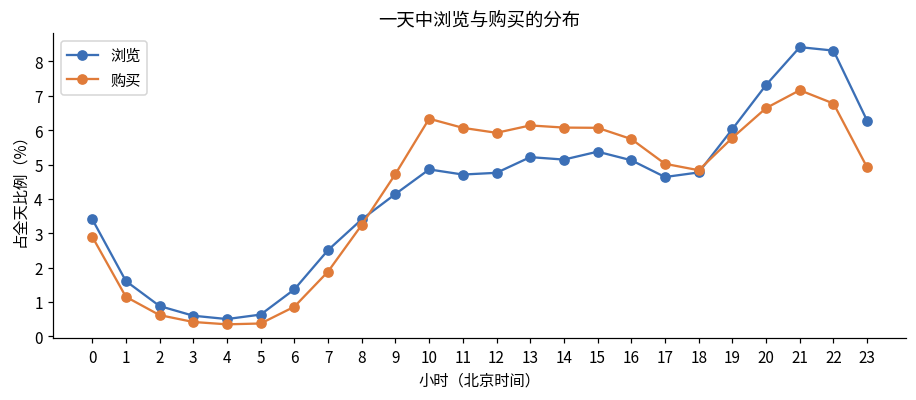

In [9]:
hourly = q('''
    SELECT
        event_hour                                                  AS 小时,
        COUNT(*) FILTER (WHERE behavior_type = 'pv')                AS 浏览量,
        COUNT(*) FILTER (WHERE behavior_type = 'buy')               AS 购买次数
    FROM ub
    GROUP BY event_hour
    ORDER BY event_hour
''')
hourly["浏览占比"] = hourly["浏览量"] / hourly["浏览量"].sum()
hourly["购买占比"] = hourly["购买次数"] / hourly["购买次数"].sum()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hourly["小时"], hourly["浏览占比"] * 100, marker="o", color=BLUE, label="浏览")
ax.plot(hourly["小时"], hourly["购买占比"] * 100, marker="o", color=ORANGE, label="购买")
ax.set_xticks(range(24))
ax.set_xlabel("小时（北京时间）")
ax.set_ylabel("占全天比例（%）")
ax.set_title("一天中浏览与购买的分布")
ax.legend()
_ = utils.save_fig(fig, "02_小时分布")

peak = hourly.nlargest(3, "浏览量")["小时"].tolist()
print(f"浏览量最高的三个小时：{sorted(peak)} 点")

## 6. 显著性检验：周末的购买转化率真的更高吗？

以"用户-天"为单位：某个用户在某一天活跃，这一天有没有购买。比较周末和工作日两组的转化率，用**两样本比例 Z 检验**判断差异是否显著。

> 数据集中 11 月 25、26 日和 12 月 2、3 日是周末。12 月初临近"双十二"预热，可能混入大促影响，解读时要注意这个混杂因素。

In [10]:
ud = q('''
    WITH user_day AS (
        SELECT
            user_id, event_date,
            ANY_VALUE(is_weekend)           AS is_weekend,
            bool_or(behavior_type = 'buy')  AS bought
        FROM ub
        GROUP BY user_id, event_date
    )
    SELECT
        CASE WHEN is_weekend THEN '周末' ELSE '工作日' END AS 分组,
        COUNT(*)                           AS 用户天数,
        SUM(CAST(bought AS INTEGER))       AS 有购买的用户天数
    FROM user_day
    GROUP BY 1
''').set_index("分组").loc[["工作日", "周末"]]
ud["转化率"] = ud["有购买的用户天数"] / ud["用户天数"]


def two_proportion_test(k1, n1, k2, n2, alpha=0.05):
    # 两样本比例 Z 检验，返回差值、置信区间、Z 值、P 值和效应量（Cohen's h）
    p1, p2 = k1 / n1, k2 / n2
    p_pool = (k1 + k2) / (n1 + n2)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se_pool
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    diff = p2 - p1
    cohen_h = 2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1))
    return {"差值": diff, "置信区间下限": diff - z_crit * se_diff, "置信区间上限": diff + z_crit * se_diff,
            "相对提升": diff / p1, "Z": z, "P值": p_value, "效应量h": cohen_h}


res = two_proportion_test(ud.loc["工作日", "有购买的用户天数"], ud.loc["工作日", "用户天数"],
                          ud.loc["周末", "有购买的用户天数"], ud.loc["周末", "用户天数"])
display(ud)
print(f"周末转化率减工作日转化率 = {res['差值'] * 100:+.3f} 个百分点"
      f"（95% 置信区间 {res['置信区间下限'] * 100:.3f} 至 {res['置信区间上限'] * 100:.3f}），"
      f"相对变化 {res['相对提升']:+.1%}，Z = {res['Z']:.2f}，P 值 = {res['P值']:.4g}，效应量 h = {res['效应量h']:.3f}")
if res["P值"] < 0.05 and abs(res["效应量h"]) < 0.2:
    print("结论：差异在统计上显著，但效应量很小（h < 0.2）。样本量很大时，再小的差异都会显著，业务上是否值得行动要看实际提升幅度。")
elif res["P值"] < 0.05:
    print("结论：差异显著，且效应量不可忽略。")
else:
    print("结论：差异不显著，不能认为周末和工作日的转化率有区别。")

,用户天数,有购买的用户天数,转化率
分组,,,
工作日,361403,"71,789.0000",0.1986
周末,336649,"61,753.0000",0.1834


周末转化率减工作日转化率 = -1.521 个百分点（95% 置信区间 -1.705 至 -1.336），相对变化 -7.7%，Z = -16.14，P 值 = 0，效应量 h = -0.039
结论：差异在统计上显著，但效应量很小（h < 0.2）。样本量很大时，再小的差异都会显著，业务上是否值得行动要看实际提升幅度。


## 7. 类目分析：哪些类目浏览多、转化低？

In [11]:
category = q('''
    SELECT
        category_id                                                 AS 类目,
        COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'pv')  AS 浏览用户数,
        COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'buy') AS 购买用户数,
        COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'buy')
            / NULLIF(COUNT(DISTINCT user_id) FILTER (WHERE behavior_type = 'pv'), 0) AS 类目转化率
    FROM ub
    GROUP BY category_id
''')
top_viewed = category.nlargest(50, "浏览用户数")
median_cr = top_viewed["类目转化率"].median()
low_conversion = top_viewed.nsmallest(5, "类目转化率")

print(f"浏览量前 50 的类目，转化率中位数为 {median_cr:.2%}")
print("浏览量前 10 的类目：")
display(category.nlargest(10, "浏览用户数"))
print("浏览量前 50 中，转化率最低的 5 个类目（高浏览、低转化）：")
low_conversion

浏览量前 50 的类目，转化率中位数为 5.59%
浏览量前 10 的类目：


,类目,浏览用户数,购买用户数,类目转化率
2054,4756105,40958,2378,0.0581
5,982926,39248,2108,0.0537
23,4145813,36574,2727,0.0746
15,2355072,35899,1060,0.0295
21,1320293,34390,1507,0.0438
2059,3607361,33094,1067,0.0322
2074,4801426,32098,2307,0.0719
16,2520377,29712,778,0.0262
17,2465336,26100,1147,0.0439
31,2735466,25431,2842,0.1118


浏览量前 50 中，转化率最低的 5 个类目（高浏览、低转化）：


,类目,浏览用户数,购买用户数,类目转化率
2073,737184,8708,65,0.0075
2048,154040,15115,207,0.0137
2067,2920476,16451,232,0.0141
2068,1080785,22676,384,0.0169
2072,1859277,11409,260,0.0228


In [12]:
o = overview.iloc[0]
f = funnel_user.set_index("环节")
paths_dict = dict(zip(paths["购买路径"], paths["占比"].round(4)))
utils.update_summary("02_SQL分析", {
    "浏览量": int(o["浏览量"]),
    "独立访客数": int(o["独立访客数"]),
    "用户购买转化率": round(float(o["用户购买转化率"]), 4),
    "复购率": round(float(o["复购率"]), 4),
    "仅浏览未互动用户占比": round(float(o["仅浏览未互动用户占比"]), 4),
    "漏斗_浏览到收藏或加购": round(float(f.loc["2 收藏或加购", "环节转化率"]), 4),
    "漏斗_收藏或加购到购买": round(float(f.loc["3 购买", "环节转化率"]), 4),
    "行为口径_浏览到收藏或加购": round(float(funnel_action.iloc[1]["环节转化率"]), 4),
    "行为口径_收藏或加购到购买": round(float(funnel_action.iloc[2]["环节转化率"]), 4),
    "购买路径占比": paths_dict,
    "加购商品的购买率": round(float(after_action.iloc[0]["加购商品的购买率"]), 4),
    "仅浏览商品的购买率": round(float(after_action.iloc[0]["仅浏览商品的购买率"]), 4),
    "首日同期群次日留存": round(float(first_cohort[1]), 4),
    "首日同期群七日留存": round(float(first_cohort[7]), 4),
    "浏览高峰小时": sorted(int(h) for h in peak),
    "周末vs工作日_转化率差值": round(float(res["差值"]), 5),
    "周末vs工作日_P值": float(res["P值"]),
    "周末vs工作日_效应量h": round(float(res["效应量h"]), 4),
    "前50类目转化率中位数": round(float(median_cr), 4),
})
print("已写入 results/summary.json")

已写入 results/summary.json


## 小结（跑完真实数据后，把结论写在这里）

- 漏斗中流失最严重的环节：
- 加购对购买的影响：
- 留存与复购：
- 时间规律与运营建议：
- 高浏览低转化类目的可能原因：

下一步：`03_用户分群_RFM与聚类.ipynb`